# Extended Data Fig. 6: Xenium healthy colon

Segger recovers neutrophils and resists epithelial contamination where nuclear segmentation fails.
Supporting analyses for Fig. 5, on the same three segmentations: 10x Cell (`cell`), 10x Nucleus (`nucleus`) and Segger (`segger`).

| | |
|---|---|
| Data | Xenium healthy colon section; the cell x gene tables and HotSpot models written by the Fig. 5 notebook |
| Compute | CUDA GPU (RAPIDS) for the neighbour graphs. Run `figure_5_xenium_healthy_colon.ipynb` first. |
| Output | `results/ed_figure_6/panel_{a,b,c,d,e,f,g,h,i,j}.{pdf,png}` |

In [1]:
import json
import logging
import pickle
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text
from scipy.cluster.hierarchy import leaves_list
from scipy.stats import spearmanr, zscore
from segger.io.utils import contours_to_polygons

import sg_utils as sg
from sg_utils.pp.preprocess_rapids import nearest_neighbors

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
palettes = json.loads((ASSETS / "palettes.json").read_text())
cell_type_palette = palettes["Cell Type"]
compartment_palette = palettes["Compartment"]
method_palette = {
    "segger": palettes["Method"]["segger"],
    "10x Nucleus": palettes["Method"]["10x Nucleus"],
    "cell": palettes["Method"]["10x Cell"],
}

In [2]:
DATA_DIR = Path("../data")
FIG5_DIR = Path("../results/figure_5")  # cell x gene tables and HotSpot models of the Fig. 5 notebook
OUT_DIR = Path("../results/ed_figure_6")

## Load the data

In [3]:
paths = sg.datasets.fetch("xenium_healthy_colon", DATA_DIR, files=["xenium"])
ad = {name: sc.read_h5ad(FIG5_DIR / f"xenium_healthy_colon_{name}.h5ad") for name in ["cell", "nucleus", "segger"]}
hs = dict()
for key in ["segger", "nucleus"]:
    with open(FIG5_DIR / f"hotspot_xenium_healthy_colon_{key}.pkl", "rb") as file:
        hs[key] = pickle.load(file)

Neutrophil-response module and cell-type neighbour counts, as in Fig. 5.

In [4]:
def compute_cell_type_neighbors(adata, connectivities_key, celltype_key):
    """Count the neighbours of each cell type for every cell, in ``adata.obsm['X_cell_type_neighbors']``."""
    connectivity = adata.obsp[connectivities_key]
    cell_types = adata.obs[celltype_key].values
    result = pd.DataFrame(index=adata.obs_names, columns=pd.unique(cell_types), dtype=float)
    for cell_type in result.columns:
        result[cell_type] = connectivity.dot((cell_types == cell_type).astype(int))
    adata.obsm["X_cell_type_neighbors"] = result


sc.tl.rank_genes_groups(
    ad["segger"], groupby="cell_type_level_1", groups=["Neutrophil"], use_raw=False, layer="lognorm", method="wilcoxon",
)
neutrophil_genes = sc.get.rank_genes_groups_df(
    ad["segger"], group="Neutrophil", log2fc_min=3, pval_cutoff=0.01,
)["names"].to_list()
for key in hs:
    modules = hs[key].modules
    hs[key].neutrophil_module = modules.groupby(modules).apply(lambda s: s.index.isin(neutrophil_genes).mean()).idxmax()
    scores = hs[key].module_scores
    ad[key].obs[[f"module_{i}" for i in scores.columns]] = scores

## Panels a and b: nuclear transcripts, nuclear area and gene detection

Per cell type, median nuclear transcripts (before the 25-transcript filter) against (a) median nuclear area and (b) genes detected after downsampling every cell to the median depth (median over 20 draws).
Points are coloured by cell type and outlined by compartment; ρ over cells.

In [5]:
vertices = pl.read_parquet(paths["xenium"] / "nucleus_boundaries.parquet")
boundaries = contours_to_polygons(
    vertices["vertex_x"].to_numpy(), vertices["vertex_y"].to_numpy(), vertices["cell_id"].to_numpy(),
)
ad["segger"].obs["nucleus_area"] = boundaries.area
unfiltered = ad["nucleus"].uns["unfiltered_counts"]
ad["segger"].obs["nucleus_counts"] = pd.Series(
    np.asarray(unfiltered["n_counts"]).flatten(), index=np.asarray(unfiltered["index"]),
)

n_iters = 20
counts_per_cell = int(ad["segger"].obs["n_counts"].median())
n_positive = []
X_backup = ad["segger"].X.copy()
for i in range(n_iters):
    ad["segger"].X = ad["segger"].layers["counts"].copy()
    sc.pp.downsample_counts(ad["segger"], counts_per_cell, random_state=i, replace=True)
    n_positive.append(np.asarray((ad["segger"].X > 0).sum(1)).flatten())
ad["segger"].X = X_backup

columns = [
    "cell_type_cluster_level_1", "cell_type_cluster_level_2", "cell_type_cluster_compartment",
    "nucleus_counts", "nucleus_area",
]
data = ad["segger"].obs[columns].copy()
data["n_genes"] = np.median(np.stack(n_positive, axis=1), axis=1)

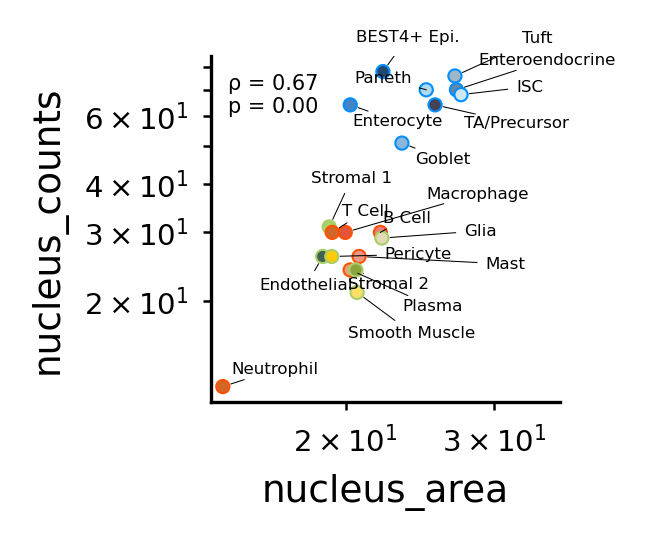

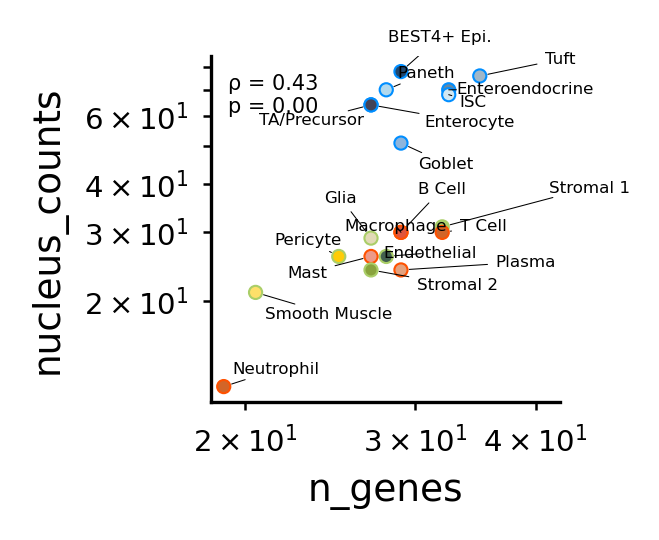

In [6]:
g, c, y = "cell_type_cluster_level_1", "cell_type_cluster_compartment", "nucleus_counts"
for panel, x in [("a", "nucleus_area"), ("b", "n_genes")]:
    fig, ax = plt.subplots(figsize=(1.5, 1.5))
    grouped = data.groupby(g).agg({x: "median", y: "median", c: lambda s: s.mode().iloc[0]})
    scatter = ax.scatter(
        grouped[x], grouped[y], edgecolors=grouped[c].map(compartment_palette),
        color=grouped.index.map(cell_type_palette), s=10, lw=0.5,
    )
    ax.set(xlabel=x, ylabel=y, xscale="log", yscale="log")
    corr, pval = spearmanr(data[x], data[y])
    ax.text(0.05, 0.95, f"ρ = {corr:.2f}\np = {pval:.2f}", transform=ax.transAxes, fontsize=5, va="top")
    texts = [ax.text(row[x], row[y], name, fontsize=4) for name, row in grouped.iterrows()]
    adjust_text(
        texts, ax=ax, objects=scatter, arrowprops=dict(arrowstyle="-", lw=0.25), expand=(1.25, 1.25),
        force_text=(2, 2), force_static=(1, 1), ensure_inside_axes=False, expand_axes=True, zorder=3,
    )
    sg.pl.save_panel(fig, OUT_DIR / f"panel_{panel}")

## Panels c and d: HotSpot local correlations

Gene-by-gene local correlation (Z) ordered by the HotSpot dendrogram, for Segger (c) and 10x Nucleus (d), with module blocks and the top genes of the neutrophil-response module.
In d, ticks mark the genes of the Segger module.

In [7]:
def plot_gene_labels(hs, genes, ax, text_height, fontsize=5):
    """Label genes with leader lines from their dendrogram position."""
    idx = leaves_list(hs.linkage)
    reordered = hs.modules.index[idx]
    positions = {gene: np.where(reordered == gene)[0][0] + 0.5 for gene in genes}
    ordered = sorted(genes, key=lambda gene: positions[gene])
    center = (min(positions.values()) + max(positions.values())) / 2
    text_start = center - text_height / 2
    text_spacing = text_height / len(genes)
    x0, x1 = ax.get_xlim()
    x_inc = (x1 - x0) / 6
    for i, gene in enumerate(ordered):
        y_gene = positions[gene]
        y_text = text_start + (i + 0.5) * text_spacing
        ax.plot([x0, x0 + x_inc, x0 + 5 * x_inc, x1], [y_gene, y_gene, y_text, y_text], color="black", lw=0.25, clip_on=False)
        ax.text(x1, y_text, f" {gene}", va="center", ha="left", fontsize=fontsize, clip_on=False)
    ax.axis("off")


def plot_module_boundaries(hs, ax):
    """Coloured strip marking each module block along the dendrogram."""
    idx = leaves_list(hs.linkage)
    modules = hs.modules.iloc[idx]
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, module in enumerate(modules.unique()):
        indices = np.where(modules == module)[0]
        start, end = indices[0], indices[-1] + 1
        ax.add_patch(plt.Rectangle((0, start), 1, end - start, facecolor=colors[i % len(colors)], edgecolor="none"))
    ax.set_xlim(0, 1)
    ax.set_ylim(len(idx), 0)
    ax.axis("off")


def top_module_genes(model, n=10):
    module_genes = model.modules.index[model.modules == model.neutrophil_module]
    z = model.local_correlation_z.loc[module_genes, module_genes]
    return z.median(0).nlargest(n).index.to_list()

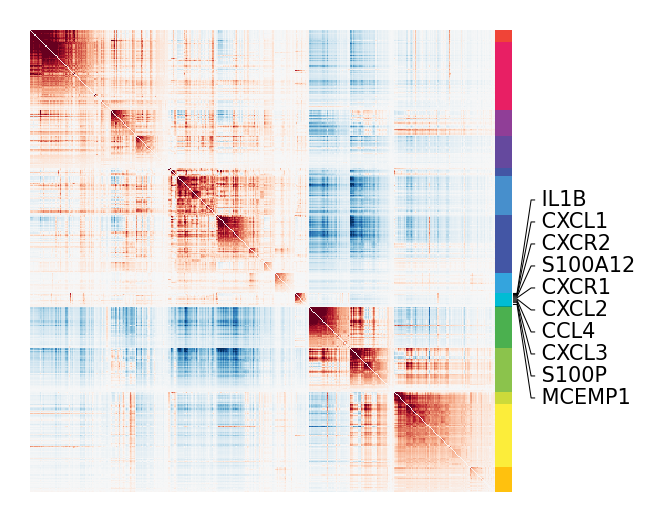

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(2.175, 2), sharey=True, gridspec_kw=dict(width_ratios=[2, 0.075, 0.1], wspace=0))
idx = leaves_list(hs["segger"].linkage)
sns.heatmap(hs["segger"].local_correlation_z.iloc[idx, idx], ax=axes[0], cmap="RdBu_r", vmin=-200, vmax=200, cbar=False)
axes[0].axis("off")
plot_module_boundaries(hs["segger"], axes[1])
plot_gene_labels(hs["segger"], top_module_genes(hs["segger"]), axes[2], 200, 5)
sg.pl.save_panel(fig, OUT_DIR / "panel_c")

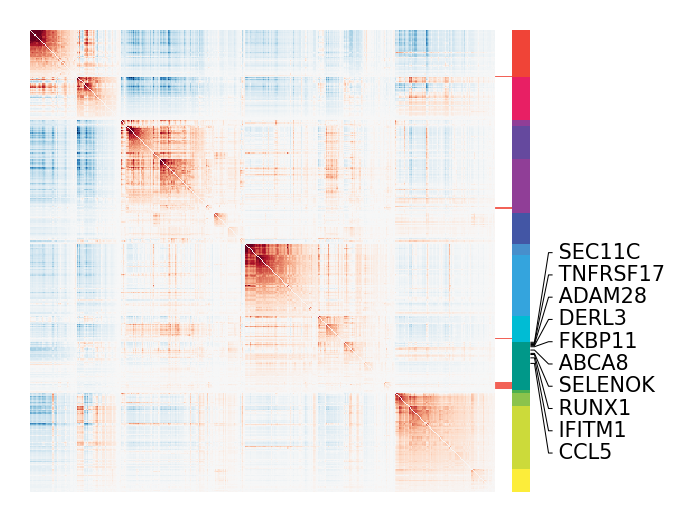

In [9]:
fig, axes = plt.subplots(
    1, 4, figsize=(2.25, 2), sharey=True, gridspec_kw=dict(width_ratios=[2, 0.075, 0.075, 0.1], wspace=0),
)
idx = leaves_list(hs["nucleus"].linkage)
sns.heatmap(hs["nucleus"].local_correlation_z.iloc[idx, idx], ax=axes[0], cmap="RdBu_r", vmin=-200, vmax=200, cbar=False)
axes[0].axis("off")
plot_module_boundaries(hs["nucleus"], axes[2])
plot_gene_labels(hs["nucleus"], top_module_genes(hs["nucleus"]), axes[3], 200, 5)
segger_genes = hs["segger"].modules.index[hs["segger"].modules == hs["segger"].neutrophil_module]
for i in np.argwhere(hs["nucleus"].modules.index[idx].isin(segger_genes)):
    axes[1].axhline(i, lw=0.2)
axes[1].axis("off")
sg.pl.save_panel(fig, OUT_DIR / "panel_d")

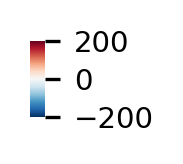

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(0.0625, 0.33))
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=-200, vmax=200), cmap="RdBu_r"),
    cax=ax, orientation="vertical", drawedges=False,
)
cbar.outline.set_visible(False)
sg.pl.save_panel(fig, OUT_DIR / "panel_cd_colorbar")

## Panels e and f: neutrophil-response module score

Module score per cell type in Segger (e) and 10x Nucleus (f).

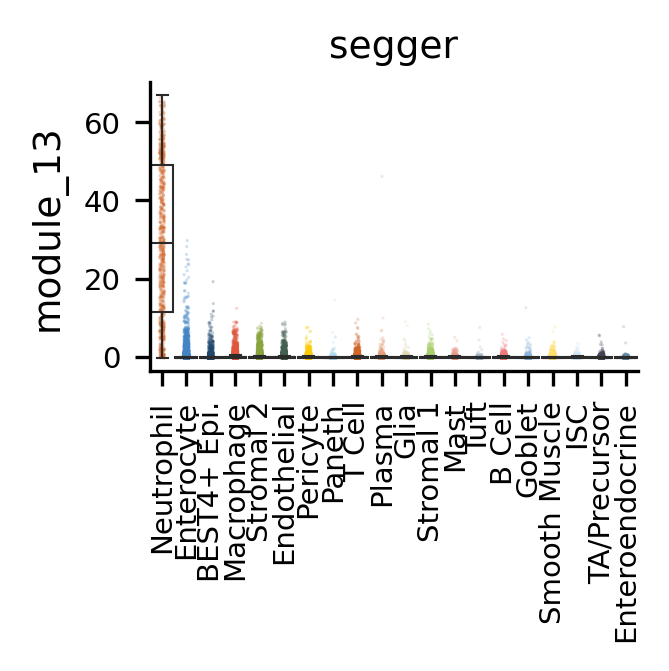

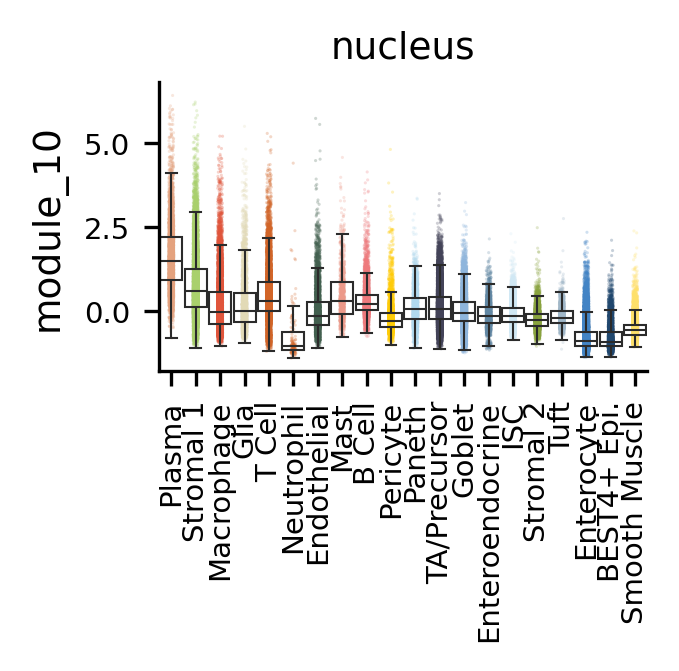

In [11]:
for panel, key in [("e", "segger"), ("f", "nucleus")]:
    fig, ax = plt.subplots(1, 1, figsize=(2.1, 1.25))
    x = "cell_type_level_1"
    y = f"module_{hs[key].neutrophil_module}"
    order = ad[key].obs.groupby(x, observed=True)[y].quantile(0.999).sort_values().index[::-1]
    sns.boxplot(
        data=ad[key].obs, x=x, y=y, order=order, hue=x, palette=cell_type_palette, width=0.9, linewidth=0.5,
        showfliers=False, boxprops=dict(fill=False), legend=False, zorder=1, ax=ax,
    )
    sns.stripplot(
        data=ad[key].obs, x=x, y=y, order=order, hue=x, palette=cell_type_palette, alpha=0.25, s=0.75,
        legend=False, zorder=0, rasterized=True, ax=ax,
    )
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel("")
    ax.set_title(key)
    sg.pl.save_panel(fig, OUT_DIR / f"panel_{panel}")

## Panel g: epithelial neighbours of CD8+ T cells

Fraction of epithelial cells among the 50 nearest expression neighbours of CD8+ T cells, 10x Cell vs Segger.

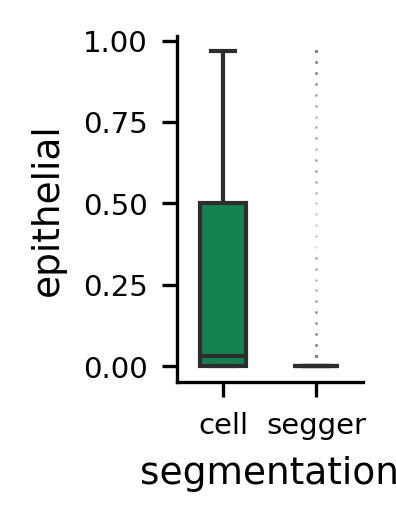

In [12]:
k = 50
neighbors = []
for key in ["segger", "cell"]:
    nearest_neighbors(ad[key], k, key_added="expr")
    compute_cell_type_neighbors(ad[key], connectivities_key="expr_connectivities", celltype_key="cell_type_compartment")
    fraction = ad[key].obsm["X_cell_type_neighbors"] / k
    mask = ad[key].obs["cell_type"].eq("CD8+ T Cell")
    fraction = fraction.loc[mask, ["epithelial"]].copy()
    fraction["segmentation"] = key
    neighbors.append(fraction)
neighbors = pd.concat(neighbors)

fig, ax = plt.subplots(1, 1, figsize=(0.8, 1.5))
sns.boxplot(
    data=neighbors, x="segmentation", y="epithelial", order=["cell", "segger"], palette=method_palette,
    hue="segmentation", legend=False, showfliers=True,
    flierprops=dict(markersize=0.5, alpha=0.1, markeredgecolor="none", markerfacecolor="gray"), width=0.5, ax=ax,
)
sg.pl.save_panel(fig, OUT_DIR / "panel_g")

## Panels h–j: CD8+ T-cell and enterocyte identity scores

Scores of the 10x Nucleus marker genes of CD8+ T cells and enterocytes in 10x Nucleus (h), Segger (i) and 10x Cell (j), for cells shared by all three.
CD8+ T cells with more than 25% epithelial expression neighbours in 10x Cell are labelled `Other`.

In [13]:
for key in ad:
    if "zscore" not in ad[key].layers:
        ad[key].layers["zscore"] = zscore(ad[key].layers["lognorm"].todense().A, axis=0)

for group in ["CD8+ T Cell", "Enterocyte"]:
    sc.tl.rank_genes_groups(
        ad["nucleus"], "cell_type", group=group, key_added=group, layer="lognorm", use_raw=False, method="wilcoxon",
    )
    degs = sc.get.rank_genes_groups_df(ad["nucleus"], group=group, key=group, pval_cutoff=1e-2, log2fc_min=np.log2(5))
    for key in ad:
        sc.tl.score_genes(ad[key], degs["names"].tolist(), use_raw=False, layer="zscore", score_name=f"{group} Score")

shared_idx = ad["nucleus"].obs_names
for key in ad:
    shared_idx = shared_idx.intersection(ad[key].obs_names)

k = 30
nearest_neighbors(ad["cell"], k, key_added="expr")
compute_cell_type_neighbors(ad["cell"], connectivities_key="expr_connectivities", celltype_key="cell_type_compartment")
epi_fraction = ad["cell"].obsm["X_cell_type_neighbors"]["epithelial"] / k
cd8_cell = ad["cell"].obs_names[ad["cell"].obs["cell_type"].eq("CD8+ T Cell")]
cd8_segger = ad["segger"].obs_names[ad["segger"].obs["cell_type"].eq("CD8+ T Cell")]
bad_idx = (
    epi_fraction.index[epi_fraction.gt(0.25)]
    .intersection(cd8_cell)
    .intersection(cd8_segger)
    .intersection(shared_idx)
)

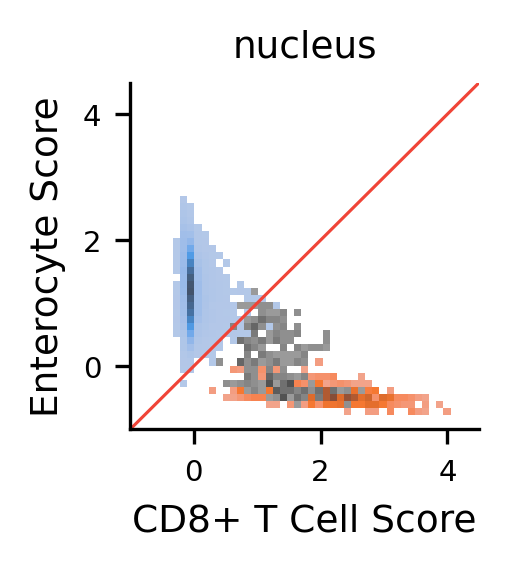

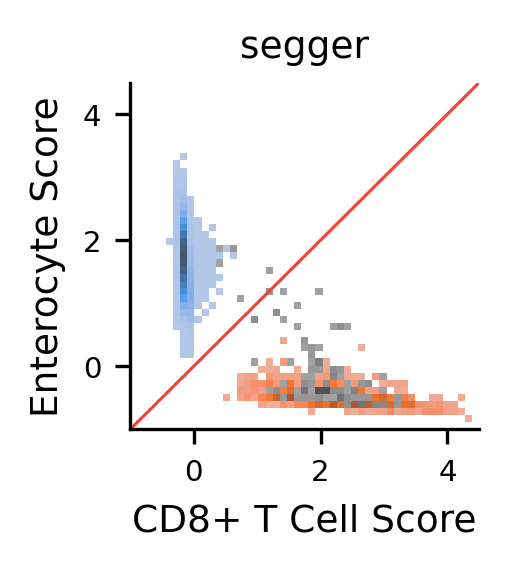

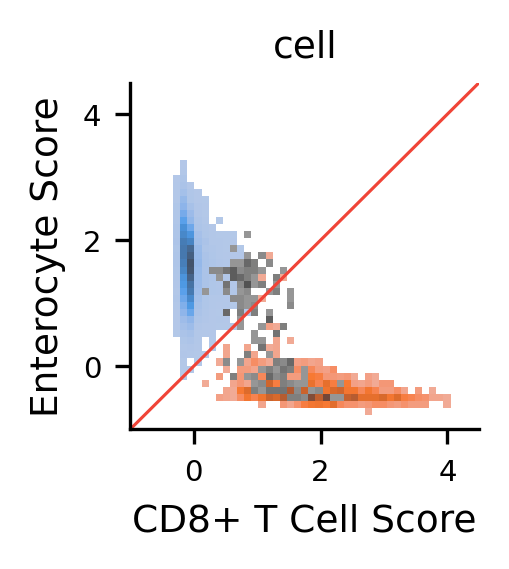

In [14]:
for key in ad:
    ad[key].obs["segger_cell_type"] = ad["segger"].obs["cell_type"].astype(str)
    ad[key].obs.loc[bad_idx, "segger_cell_type"] = "Other"

hue_order = ["Enterocyte", "CD8+ T Cell", "Other"]
palette = [cell_type_palette["Enterocyte"], cell_type_palette["T Cell"], "k"]
for panel, key in [("h", "nucleus"), ("i", "segger"), ("j", "cell")]:
    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
    mask = ad[key].obs["segger_cell_type"].isin(hue_order)
    sns.histplot(
        ad[key].obs[mask], x="CD8+ T Cell Score", y="Enterocyte Score", hue="segger_cell_type", hue_order=hue_order,
        palette=palette, common_norm=False, legend=False, bins=[np.linspace(-1, 4.5, 50)] * 2, thresh=3,
        rasterized=True, ax=ax,
    )
    ax.plot([-1, 4.5], [-1, 4.5])
    ax.set_xlim(-1, 4.5)
    ax.set_ylim(-1, 4.5)
    ax.set_title(key)
    sg.pl.save_panel(fig, OUT_DIR / f"panel_{panel}")

## Software versions

In [15]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
matplotlib,3.10.8
numpy,1.26.4
pandas,2.2.2
polars,1.40.0
scanpy,1.11.5
seaborn,0.13.2
adjustText,1.4.0
scipy,1.17.1
segger,0.1.0
geopandas,1.1.3
